# People Flow Counter & Heatmap 

In [1]:
%pip install -q ultralytics opencv-python numpy matplotlib imageio-ffmpeg


Note: you may need to restart the kernel to use updated packages.


In [2]:
%matplotlib inline
from pathlib import Path
from urllib.request import Request, urlopen
from collections import deque
from tempfile import TemporaryDirectory
import subprocess

import cv2
import numpy as np
import matplotlib.pyplot as plt
from ultralytics import YOLO
from imageio_ffmpeg import get_ffmpeg_exe


In [ ]:
VIDEO_URL = "https://media.roboflow.com/supervision/video-examples/people-walking.mp4"
INPUT_PATH = "input/people-walking.mp4"
OUTPUT_PATH = "output/people-walking-detection.mp4"
HEATMAP_PATH = "output/people-walking-heatmap.png"

UPPER = 0.36
LOWER = 0.65
LINE_MARGIN = 6
CONFIRM_FRAMES = 2


## Download Video


In [4]:
def download_video():
    if Path(INPUT_PATH).exists() and Path(INPUT_PATH).stat().st_size > 0:
        return

    request = Request(VIDEO_URL, headers={"User-Agent": "Mozilla/5.0"})
    with urlopen(request) as response:
        Path(INPUT_PATH).write_bytes(response.read())

    print("Video downloaded.")


download_video()


## Load & Inspect First Frame


In [5]:
video = cv2.VideoCapture(INPUT_PATH)
ok, first_frame = video.read()
fps = video.get(cv2.CAP_PROP_FPS)
video.release()

if not ok or fps <= 0:
    raise RuntimeError("Cannot read the input video.")

height, width = first_frame.shape[:2]
upper_y = int(height * UPPER)
lower_y = int(height * LOWER)
max_gap = round(fps * 0.5)
print(f"Video: {width} x {height} | FPS: {fps:g}")


Video: 1920 x 1080 | FPS: 25


## Line Crossing Logic


In [6]:
def update_line(state, current_y, line_y, direction):
    side = -1 if current_y < line_y - LINE_MARGIN else (
        1 if current_y > line_y + LINE_MARGIN else 0)

    if side == 0 or side == state["side"]:
        state["candidate"], state["hits"] = 0, 0
        return False

    state["hits"] = state["hits"] + 1 if side == state["candidate"] else 1
    state["candidate"] = side
    if state["hits"] < CONFIRM_FRAMES:
        return False

    previous_side = state["side"]
    state["side"] = side
    state["candidate"], state["hits"] = 0, 0
    if direction == "down":
        return previous_side == -1 and side == 1
    return previous_side == 1 and side == -1


def update_counts(obj_id, center, frame_number):
    track = previous_positions.get(obj_id)
    if track is None or frame_number - track["last_seen"] > max_gap:
        track = {"ys": deque(maxlen=3), "last_seen": frame_number, "center": center,
                 "IN": {"side": None, "candidate": 0, "hits": 0},
                 "OUT": {"side": None, "candidate": 0, "hits": 0}}
        previous_positions[obj_id] = track

    track["center"] = center
    track["last_seen"] = frame_number
    track["ys"].append(center[1])
    current_y = float(np.median(track["ys"]))

    if update_line(track["IN"], current_y, upper_y, "down"):
        counted_in.add(obj_id)
    if update_line(track["OUT"], current_y, lower_y, "up"):
        counted_out.add(obj_id)


## Drawing Overlays


In [7]:
def draw_person(frame, box, obj_id):
    x1, y1, x2, y2 = map(int, box)
    cv2.rectangle(frame, (x1, y1), (x2, y2), (255, 0, 0), 2)
    cv2.putText(frame, f"ID: {obj_id}", (max(0, x1), max(18, y1 - 8)),
                cv2.FONT_HERSHEY_SIMPLEX, 0.5, (255, 0, 0), 2)


def draw_lines(frame):
    for y, label, color in [(upper_y, "UPPER / IN", (0, 220, 0)),
                            (lower_y, "LOWER / OUT", (0, 0, 255))]:
        cv2.line(frame, (0, y), (width - 1, y), color, 2)
        cv2.putText(frame, label, (12, y - 8), cv2.FONT_HERSHEY_SIMPLEX, 0.6, color, 2)


def draw_counts(frame):
    cv2.rectangle(frame, (10, 10), (250, 80), (0, 0, 0), -1)
    cv2.putText(frame, f"IN: {len(counted_in)}", (20, 40),
                cv2.FONT_HERSHEY_SIMPLEX, 0.8, (0, 255, 0), 2)
    cv2.putText(frame, f"OUT: {len(counted_out)}", (20, 70),
                cv2.FONT_HERSHEY_SIMPLEX, 0.8, (0, 0, 255), 2)


## Heatmap Generation


In [8]:
def build_heatmap(frame, visits):
    blurred = cv2.GaussianBlur(visits, (0, 0), sigmaX=35, sigmaY=35)
    strength = cv2.normalize(blurred, None, 0, 1, cv2.NORM_MINMAX)
    heat = np.uint8(np.sqrt(strength) * 255)
    colors = cv2.applyColorMap(heat, cv2.COLORMAP_JET)
    alpha = (0.75 * heat / 255)[..., None]
    overlay = np.uint8(frame * (1 - alpha) + colors * alpha)

    cv2.rectangle(overlay, (0, 0), (width, 48), (20, 20, 20), -1)
    cv2.putText(overlay, f"PRESENCE HEATMAP | IN: {len(counted_in)} | OUT: {len(counted_out)}",
                (12, 32), cv2.FONT_HERSHEY_SIMPLEX, 0.65, (255, 255, 255), 2)
    return overlay


## Video Export


In [9]:
def save_video(raw_path):
    command = [get_ffmpeg_exe(), "-y", "-i", str(raw_path),
               "-c:v", "libx264", "-preset", "fast", "-crf", "20",
               "-pix_fmt", "yuv420p", "-movflags", "+faststart", "-an", OUTPUT_PATH]
    result = subprocess.run(command, capture_output=True, text=True)
    if result.returncode:
        raise RuntimeError(result.stderr[-1000:])


## Run Detection & Tracking


In [10]:
model = YOLO("yolo11n.pt")
previous_positions = {}
counted_in = set()
counted_out = set()
visits = np.zeros((height, width), dtype=np.float32)
frame_number = 0

with TemporaryDirectory() as temporary_folder:
    raw_path = Path(temporary_folder) / "frames.mp4"
    video = cv2.VideoCapture(INPUT_PATH)
    writer = cv2.VideoWriter(str(raw_path), cv2.VideoWriter_fourcc(*"mp4v"), fps, (width, height))
    if not video.isOpened() or not writer.isOpened():
        video.release()
        writer.release()
        raise RuntimeError("Cannot open the video reader or writer.")

    try:
        while True:
            ok, frame = video.read()
            if not ok:
                break

            results = model.track(frame, persist=True, tracker="bytetrack.yaml",
                                  classes=[0], conf=0.1, imgsz=960, verbose=False)[0]
            if results.boxes is not None and results.boxes.id is not None:
                boxes = results.boxes.xyxy.cpu().numpy()
                ids = results.boxes.id.cpu().numpy().astype(int)

                for box, obj_id in zip(boxes, ids):
                    x1, y1, x2, y2 = box
                    cx = int(np.clip((x1 + x2) / 2, 0, width - 1))
                    cy = int(np.clip((y1 + y2) / 2, 0, height - 1))
                    update_counts(obj_id, (cx, cy), frame_number)
                    visits[cy, cx] += 1
                    draw_person(frame, box, obj_id)

            previous_positions = {i: p for i, p in previous_positions.items()
                                  if frame_number - p["last_seen"] <= max_gap}
            draw_lines(frame)
            draw_counts(frame)
            writer.write(frame)
            frame_number += 1
    finally:
        video.release()
        writer.release()

    save_video(raw_path)

print(f"Processed {frame_number} frames | IN: {len(counted_in)} | OUT: {len(counted_out)}")
print(f"Saved {OUTPUT_PATH}")


Processed 341 frames | IN: 11 | OUT: 9
Saved people-walking-detection.mp4


## Save Heatmap


In [11]:
heatmap_img = build_heatmap(first_frame, visits)
if not cv2.imwrite(HEATMAP_PATH, heatmap_img):
    raise RuntimeError("Cannot save the heatmap.")
print(f"Saved {HEATMAP_PATH}")


Saved people-walking-heatmap.png


## Preview Heatmap


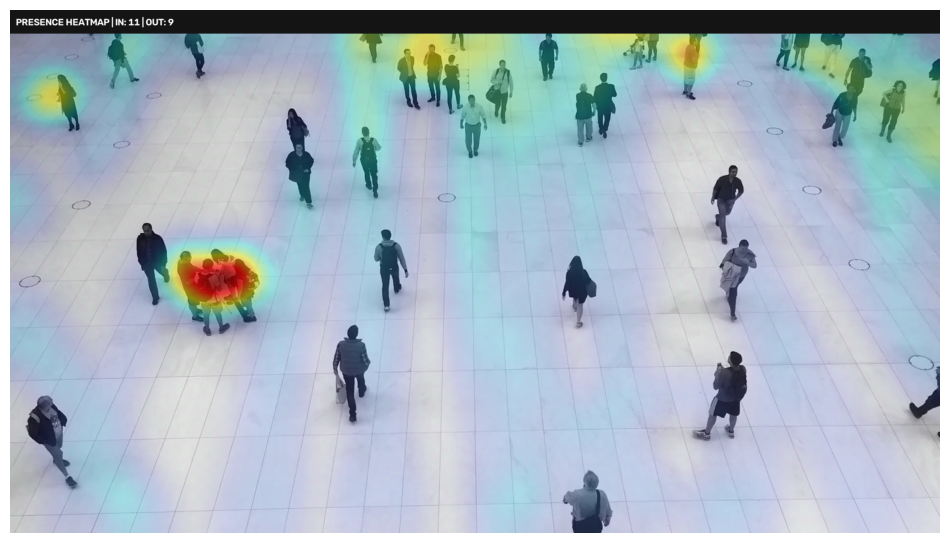

In [12]:
plt.figure(figsize=(12, 8))
plt.imshow(cv2.cvtColor(heatmap_img, cv2.COLOR_BGR2RGB))
plt.axis("off")
plt.show()
